In [76]:
#Import the libraries we need to get started
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [77]:
#Read in the data
data = pd.read_csv("../EURUSD Detailed Market Data As Series Moving Average.csv")
data

,Time,True Open,True High,True Low,True Close,True MA O,True MA H,True MA L,True MA C,Diff Open,...,Diff MA Open 2,Diff MA High 2,Diff MA Low 2,Diff MA Close 2,O-C,H-L,O-H,O-L,C-H,C-L
0,2010.06.07 00:00:00,1.19460,1.19907,1.18758,1.19166,1.217488,1.223044,1.205370,1.210116,-0.03347,...,-0.012886,-0.015720,-0.014956,-0.019236,0.00294,0.01149,-0.00447,0.00702,-0.00741,0.00408
1,2010.06.08 00:00:00,1.19165,1.20080,1.19022,1.19640,1.209696,1.216230,1.201200,1.205166,-0.03896,...,-0.019818,-0.021754,-0.017788,-0.021008,-0.00475,0.01058,-0.00915,0.00143,-0.00440,0.00618
2,2010.06.09 00:00:00,1.19636,1.20724,1.19236,1.19840,1.204742,1.212226,1.196174,1.199862,-0.02477,...,-0.021580,-0.023792,-0.023238,-0.028078,-0.00204,0.01488,-0.01088,0.00400,-0.00884,0.00604
3,2010.06.10 00:00:00,1.19834,1.21411,1.19565,1.21081,1.199422,1.208544,1.192264,1.198796,-0.02660,...,-0.028658,-0.026104,-0.027120,-0.025246,-0.01247,0.01846,-0.01577,0.00269,-0.00330,0.01516
4,2010.06.11 00:00:00,1.21074,1.21521,1.20452,1.21112,1.198338,1.207286,1.194066,1.201678,-0.00542,...,-0.025844,-0.022626,-0.019118,-0.016266,-0.00038,0.01069,-0.00447,0.00622,-0.00409,0.00660
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3995,2025.10.21 00:00:00,1.16389,1.16553,1.15975,1.15988,1.164586,1.168012,1.162466,1.164456,0.00740,...,0.004484,0.004316,0.006796,0.004624,0.00401,0.00578,-0.00164,0.00414,-0.00565,0.00013
3996,2025.10.22 00:00:00,1.15965,1.16224,1.15768,1.16089,1.164434,1.167512,1.161968,1.163702,-0.00076,...,0.005306,0.004082,0.006226,0.003494,-0.00124,0.00456,-0.00259,0.00197,-0.00135,0.00321
3997,2025.10.23 00:00:00,1.16079,1.16201,1.15852,1.16175,1.163756,1.166032,1.160948,1.162316,-0.00339,...,0.004254,0.001688,0.003318,-0.000344,-0.00096,0.00349,-0.00122,0.00227,-0.00026,0.00323
3998,2025.10.24 00:00:00,1.16152,1.16489,1.16008,1.16253,1.162414,1.164448,1.159974,1.161818,-0.00671,...,0.000328,-0.001848,0.000224,-0.001392,-0.00101,0.00481,-0.00337,0.00144,-0.00236,0.00245


In [78]:
data.columns

Index(['Time', 'True Open', 'True High', 'True Low', 'True Close', 'True MA O',
       'True MA H', 'True MA L', 'True MA C', 'Diff Open', 'Diff High',
       'Diff Low', 'Diff Close', 'Diff MA Open 2', 'Diff MA High 2',
       'Diff MA Low 2', 'Diff MA Close 2', 'O-C', 'H-L', 'O-H', 'O-L', 'C-H',
       'C-L'],
      dtype='object')

In [79]:
#Classical Target
#V1 value 
HORIZON = 10

#Label the data
data['Target 1'] = data['True MA C'].shift(-1)
data['Target 2'] = data['True MA C'].shift(-HORIZON)

#Drop the last batch of forecasts
data = data.iloc[:-HORIZON,:]
data

,Time,True Open,True High,True Low,True Close,True MA O,True MA H,True MA L,True MA C,Diff Open,...,Diff MA Low 2,Diff MA Close 2,O-C,H-L,O-H,O-L,C-H,C-L,Target 1,Target 2
0,2010.06.07 00:00:00,1.19460,1.19907,1.18758,1.19166,1.217488,1.223044,1.205370,1.210116,-0.03347,...,-0.014956,-0.019236,0.00294,0.01149,-0.00447,0.00702,-0.00741,0.00408,1.205166,1.234236
1,2010.06.08 00:00:00,1.19165,1.20080,1.19022,1.19640,1.209696,1.216230,1.201200,1.205166,-0.03896,...,-0.017788,-0.021008,-0.00475,0.01058,-0.00915,0.00143,-0.00440,0.00618,1.199862,1.233128
2,2010.06.09 00:00:00,1.19636,1.20724,1.19236,1.19840,1.204742,1.212226,1.196174,1.199862,-0.02477,...,-0.023238,-0.028078,-0.00204,0.01488,-0.01088,0.00400,-0.00884,0.00604,1.198796,1.233354
3,2010.06.10 00:00:00,1.19834,1.21411,1.19565,1.21081,1.199422,1.208544,1.192264,1.198796,-0.02660,...,-0.027120,-0.025246,-0.01247,0.01846,-0.01577,0.00269,-0.00330,0.01516,1.201678,1.232318
4,2010.06.11 00:00:00,1.21074,1.21521,1.20452,1.21112,1.198338,1.207286,1.194066,1.201678,-0.00542,...,-0.019118,-0.016266,-0.00038,0.01069,-0.00447,0.00622,-0.00409,0.00660,1.207606,1.231930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3985,2025.10.07 00:00:00,1.17088,1.17152,1.16468,1.16566,1.171940,1.174854,1.168170,1.171112,-0.00150,...,-0.000506,-0.000080,0.00522,0.00684,-0.00064,0.00620,-0.00586,0.00098,1.169068,1.164456
3986,2025.10.08 00:00:00,1.16528,1.16607,1.15981,1.16278,1.170318,1.172490,1.165828,1.169068,-0.00811,...,-0.002594,-0.001984,0.00250,0.00626,-0.00079,0.00547,-0.00329,0.00297,1.166030,1.163702
3987,2025.10.09 00:00:00,1.16231,1.16484,1.15418,1.15642,1.168222,1.170288,1.163004,1.166030,-0.01048,...,-0.006174,-0.006054,0.00589,0.01066,-0.00253,0.00813,-0.00842,0.00224,1.163664,1.162316
3988,2025.10.10 00:00:00,1.15531,1.16305,1.15435,1.16227,1.165038,1.167716,1.159644,1.163664,-0.01592,...,-0.010744,-0.009260,-0.00696,0.00870,-0.00774,0.00096,-0.00078,0.00792,1.160818,1.161818


In [80]:
#Drop the last 3 years of data
test = data.iloc[-(365*3):,:]
data = data.iloc[:-(365*3),:]
data

,Time,True Open,True High,True Low,True Close,True MA O,True MA H,True MA L,True MA C,Diff Open,...,Diff MA Low 2,Diff MA Close 2,O-C,H-L,O-H,O-L,C-H,C-L,Target 1,Target 2
0,2010.06.07 00:00:00,1.19460,1.19907,1.18758,1.19166,1.217488,1.223044,1.205370,1.210116,-0.03347,...,-0.014956,-0.019236,0.00294,0.01149,-0.00447,0.00702,-0.00741,0.00408,1.205166,1.234236
1,2010.06.08 00:00:00,1.19165,1.20080,1.19022,1.19640,1.209696,1.216230,1.201200,1.205166,-0.03896,...,-0.017788,-0.021008,-0.00475,0.01058,-0.00915,0.00143,-0.00440,0.00618,1.199862,1.233128
2,2010.06.09 00:00:00,1.19636,1.20724,1.19236,1.19840,1.204742,1.212226,1.196174,1.199862,-0.02477,...,-0.023238,-0.028078,-0.00204,0.01488,-0.01088,0.00400,-0.00884,0.00604,1.198796,1.233354
3,2010.06.10 00:00:00,1.19834,1.21411,1.19565,1.21081,1.199422,1.208544,1.192264,1.198796,-0.02660,...,-0.027120,-0.025246,-0.01247,0.01846,-0.01577,0.00269,-0.00330,0.01516,1.201678,1.232318
4,2010.06.11 00:00:00,1.21074,1.21521,1.20452,1.21112,1.198338,1.207286,1.194066,1.201678,-0.00542,...,-0.019118,-0.016266,-0.00038,0.01069,-0.00447,0.00622,-0.00409,0.00660,1.207606,1.231930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2890,2021.07.23 00:00:00,1.17705,1.17865,1.17544,1.17689,1.178884,1.180966,1.175672,1.178268,-0.00413,...,-0.003702,-0.003536,0.00016,0.00321,-0.00160,0.00161,-0.00176,0.00145,1.178352,1.183260
2891,2021.07.26 00:00:00,1.17677,1.18173,1.17635,1.18029,1.178130,1.180826,1.175662,1.178352,-0.00377,...,-0.002270,-0.002214,-0.00352,0.00538,-0.00496,0.00042,-0.00144,0.00394,1.179072,1.180608
2892,2021.07.27 00:00:00,1.18030,1.18411,1.17701,1.18165,1.178230,1.181598,1.175948,1.179072,0.00050,...,-0.001652,-0.001574,-0.00135,0.00710,-0.00381,0.00329,-0.00246,0.00464,1.180062,1.177740
2893,2021.07.28 00:00:00,1.18159,1.18494,1.17721,1.18441,1.178956,1.182492,1.176352,1.180062,0.00363,...,-0.000848,0.000240,-0.00282,0.00773,-0.00335,0.00438,-0.00053,0.00720,1.182378,1.175782


Text(0.5, 1.0, 'Analyzing Market Correlation Strucute')

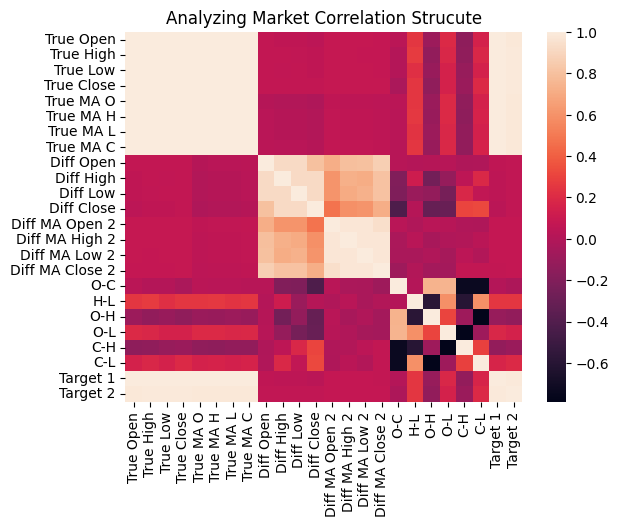

In [81]:
sns.heatmap(data.iloc[:,1:].corr())
plt.title('Analyzing Market Correlation Strucute')

In [82]:
data.corr()

C:\Users\Westwood\AppData\Local\Temp\ipykernel_11168\2627137660.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  data.corr()


,True Open,True High,True Low,True Close,True MA O,True MA H,True MA L,True MA C,Diff Open,Diff High,...,Diff MA Low 2,Diff MA Close 2,O-C,H-L,O-H,O-L,C-H,C-L,Target 1,Target 2
True Open,1.000000,0.999163,0.999160,0.998162,0.997781,0.998213,0.998257,0.998835,0.067875,0.056226,...,0.078807,0.075439,0.033432,0.247599,-0.095250,0.195774,-0.145221,0.149483,0.999226,0.985796
True High,0.999163,1.000000,0.998885,0.999174,0.997017,0.997940,0.997420,0.998422,0.066966,0.066512,...,0.078716,0.077513,0.002938,0.270470,-0.135879,0.182190,-0.141040,0.180994,0.999140,0.986681
True Low,0.999160,0.998885,1.000000,0.999188,0.996983,0.997345,0.997956,0.998393,0.067482,0.061570,...,0.081435,0.078527,0.002658,0.224712,-0.108823,0.155415,-0.113406,0.154169,0.999144,0.986584
True Close,0.998162,0.999174,0.999188,1.000000,0.996064,0.996842,0.996882,0.997818,0.066594,0.068797,...,0.080838,0.080675,-0.027197,0.247256,-0.140041,0.150810,-0.100701,0.193864,0.998893,0.987430
True MA O,0.997781,0.997017,0.996983,0.996064,1.000000,0.999755,0.999746,0.999647,0.014182,0.001555,...,0.046614,0.037185,0.031425,0.247682,-0.096762,0.194366,-0.143777,0.151034,0.998732,0.984022
True MA H,0.998213,0.997940,0.997345,0.996842,0.999755,1.000000,0.999428,0.999746,0.024113,0.013949,...,0.053464,0.045995,0.025736,0.259350,-0.108761,0.196121,-0.147443,0.161276,0.999099,0.984750
True MA L,0.998257,0.997420,0.997956,0.996882,0.999746,0.999428,1.000000,0.999751,0.024982,0.013717,...,0.055918,0.046968,0.025800,0.236155,-0.095029,0.182565,-0.133722,0.147389,0.999120,0.984598
True MA C,0.998835,0.998422,0.998393,0.997818,0.999647,0.999746,0.999751,1.000000,0.034848,0.025494,...,0.062135,0.055812,0.019886,0.247915,-0.105422,0.186025,-0.135441,0.159700,0.999643,0.985611
Diff Open,0.067875,0.066966,0.067482,0.066594,0.014182,0.024113,0.024982,0.034848,1.000000,0.916730,...,0.800636,0.865667,0.021332,0.006067,0.014285,0.021330,-0.017148,-0.010010,0.050853,0.061331
Diff High,0.056226,0.066512,0.061570,0.068797,0.001555,0.013949,0.013717,0.025494,0.916730,1.000000,...,0.709682,0.807758,-0.207155,0.117252,-0.256887,-0.117981,0.047640,0.187909,0.044318,0.062489


Text(0.5, 1.0, 'Spectrum Analysis of The EURUSD Market')

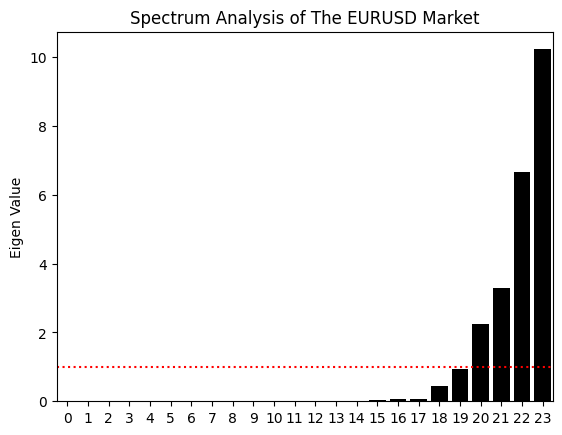

In [83]:
eig_val ,eig_vec =np.linalg.eigh(data.iloc[:,1:].corr())
sns.barplot(eig_val,color='black')
plt.axhline(np.mean(eig_val),color='red',linestyle=':')
plt.ylabel('Eigen Value')
plt.title('Spectrum Analysis of The EURUSD Market')

In [84]:
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.svm import LinearSVR
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import GradientBoostingRegressor,RandomForestRegressor

In [85]:
X = data.iloc[:,1:-2].columns
y = ['Target 1','Target 2']

In [86]:
model = RandomForestRegressor(random_state=0,max_depth=5,n_estimators=50)
model.fit(data.loc[:,X],data[y])

,n_estimators,50
,criterion,'squared_error'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [87]:
import onnx
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType

In [88]:
initial_types = [('float_input',FloatTensorType([1,len(X)]))]
final_types = [('float_output',FloatTensorType([1,2]))]

In [89]:
onnx_proto = convert_sklearn(model,initial_types=initial_types,final_types=final_types,target_opset=12)

In [90]:
onnx.save(onnx_proto,"EURUSD 2022-2025 RFR V5.onnx")

In [9]:
len(X)

22